Create a feature importance report by manually ranking feature contributions using multiple interpretability techniques, comparing global and local importance scores, and justifying feature selection in a technical document.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import itertools
import math
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target]).copy()

X = df[features]
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=42
    )
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("F1 score:", round(f1_score(y_test, predictions), 4))
print("Model training completed.")

Accuracy: 0.75
F1 score: 0.8333
Model training completed.


In [2]:
baseline_f1 = f1_score(y_test, model.predict(X_test))

rng = np.random.default_rng(42)
permutation_results = []

for feature in features:
    score_drops = []

    for repeat in range(10):
        shuffled_X = X_test.copy()

        shuffled_X[feature] = rng.permutation(
            shuffled_X[feature].to_numpy()
        )

        shuffled_f1 = f1_score(
            y_test,
            model.predict(shuffled_X),
            zero_division=0
        )

        score_drops.append(baseline_f1 - shuffled_f1)

    permutation_results.append({
        "Feature": feature,
        "Mean F1 Decrease": np.mean(score_drops),
        "Std F1 Decrease": np.std(score_drops)
    })

permutation_df = pd.DataFrame(permutation_results)

permutation_df = permutation_df.sort_values(
    "Mean F1 Decrease",
    ascending=False
)

print(permutation_df.round(5).to_string(index=False))

 Feature  Mean F1 Decrease  Std F1 Decrease
     age           0.07151          0.05251
 oldpeak           0.00000          0.00000
    chol          -0.01826          0.03182
 thalach          -0.03267          0.02139
trestbps          -0.05091          0.02500


In [3]:
background = X_train.sample(
    n=min(20, len(X_train)),
    random_state=42
).reset_index(drop=True)

def predict_probability(data):
    data = pd.DataFrame(data, columns=features)
    return model.predict_proba(data)[:, 1]

def manual_shapley_values(patient):
    n = len(features)
    values = np.zeros(n)
    patient_values = patient[features].to_numpy(dtype=float)

    for i in range(n):
        other_features = [j for j in range(n) if j != i]

        for size in range(n):
            for subset in itertools.combinations(other_features, size):
                weight = (
                    math.factorial(size)
                    * math.factorial(n - size - 1)
                    / math.factorial(n)
                )

                without_i = background.copy()
                with_i = background.copy()

                for j in subset:
                    without_i.iloc[:, j] = patient_values[j]
                    with_i.iloc[:, j] = patient_values[j]

                with_i.iloc[:, i] = patient_values[i]

                values[i] += weight * (
                    predict_probability(with_i).mean()
                    - predict_probability(without_i).mean()
                )

    return values

# Calculate global SHAP importance on a sample of test patients.
shap_patients = X_test.iloc[:min(15, len(X_test))]

shap_values_list = [
    manual_shapley_values(patient)
    for _, patient in shap_patients.iterrows()
]

shap_values_df = pd.DataFrame(
    shap_values_list,
    columns=features,
    index=shap_patients.index
)

shap_importance = shap_values_df.abs().mean().rename(
    "Mean Absolute SHAP"
)

print(shap_importance.sort_values(ascending=False).round(5))

age         0.12708
chol        0.10372
trestbps    0.06838
oldpeak     0.05302
thalach     0.02087
Name: Mean Absolute SHAP, dtype: float64


In [4]:
def manual_lime_values(patient, seed=42, n_samples=1500):
    rng = np.random.default_rng(seed)

    means = X_train.mean().to_numpy()
    stds = X_train.std().to_numpy()
    stds = np.where(stds == 0, 1.0, stds)

    x = patient[features].to_numpy(dtype=float)

    samples = x + rng.normal(
        size=(n_samples, len(features))
    ) * stds

    samples = np.clip(
        samples,
        X_train.min().to_numpy(),
        X_train.max().to_numpy()
    )

    probabilities = predict_probability(
        pd.DataFrame(samples, columns=features)
    )

    Z = (samples - means) / stds
    z_patient = (x - means) / stds

    distances = np.sqrt(
        np.sum((Z - z_patient) ** 2, axis=1)
    )

    kernel_width = 0.75 * np.sqrt(len(features))
    weights = np.exp(
        -(distances ** 2) / (kernel_width ** 2)
    )

    design = np.column_stack([np.ones(n_samples), Z])

    weighted_design = design * np.sqrt(weights[:, None])
    weighted_y = probabilities * np.sqrt(weights)

    penalty = np.eye(design.shape[1])
    penalty[0, 0] = 0

    coefficients = np.linalg.solve(
        weighted_design.T @ weighted_design + penalty,
        weighted_design.T @ weighted_y
    )

    local_mean = np.average(Z, axis=0, weights=weights)

    contributions = coefficients[1:] * (
        z_patient - local_mean
    )

    return contributions

lime_patients = X_test.iloc[:min(15, len(X_test))]

lime_values_df = pd.DataFrame(
    [
        manual_lime_values(patient, seed=100 + i)
        for i, (_, patient) in enumerate(lime_patients.iterrows())
    ],
    columns=features,
    index=lime_patients.index
)

lime_importance = lime_values_df.abs().mean().rename(
    "Mean Absolute LIME"
)

print(lime_importance.sort_values(ascending=False).round(5))

age         0.00890
chol        0.00357
trestbps    0.00289
thalach     0.00239
oldpeak     0.00187
Name: Mean Absolute LIME, dtype: float64


In [5]:
importance_df = pd.concat(
    [
        permutation_df.set_index("Feature")["Mean F1 Decrease"],
        shap_importance,
        lime_importance
    ],
    axis=1
)

importance_df["Permutation Rank"] = (
    importance_df["Mean F1 Decrease"]
    .rank(ascending=False, method="average")
)

importance_df["SHAP Rank"] = (
    importance_df["Mean Absolute SHAP"]
    .rank(ascending=False, method="average")
)

importance_df["LIME Rank"] = (
    importance_df["Mean Absolute LIME"]
    .rank(ascending=False, method="average")
)

importance_df["Average Rank"] = importance_df[
    ["Permutation Rank", "SHAP Rank", "LIME Rank"]
].mean(axis=1)

importance_df = importance_df.sort_values("Average Rank")

print(importance_df.round(5).to_string())

          Mean F1 Decrease  Mean Absolute SHAP  Mean Absolute LIME  Permutation Rank  SHAP Rank  LIME Rank  Average Rank
age                0.07151             0.12708             0.00890               1.0        1.0        1.0       1.00000
chol              -0.01826             0.10372             0.00357               3.0        2.0        2.0       2.33333
oldpeak            0.00000             0.05302             0.00187               2.0        4.0        5.0       3.66667
trestbps          -0.05091             0.06838             0.00289               5.0        3.0        3.0       3.66667
thalach           -0.03267             0.02087             0.00239               4.0        5.0        4.0       4.33333


In [6]:
patient_position = 0
patient = X_test.iloc[patient_position]

local_shap = manual_shapley_values(patient)
local_lime = manual_lime_values(patient, seed=42)

local_df = pd.DataFrame({
    "Feature": features,
    "SHAP Contribution": local_shap,
    "LIME Contribution": local_lime
})

local_df["SHAP Absolute Impact"] = local_df[
    "SHAP Contribution"
].abs()

local_df["LIME Absolute Impact"] = local_df[
    "LIME Contribution"
].abs()

local_df = local_df.sort_values(
    "SHAP Absolute Impact",
    ascending=False
)

print("Selected patient index:", patient.name)
print("Predicted class:", model.predict(patient.to_frame().T)[0])
print(
    "Predicted probability of class 1:",
    round(model.predict_proba(patient.to_frame().T)[0, 1], 4)
)
print(local_df.round(5).to_string(index=False))

Selected patient index: 49
Predicted class: 0
Predicted probability of class 1: 0.33
 Feature  SHAP Contribution  LIME Contribution  SHAP Absolute Impact  LIME Absolute Impact
     age           -0.40362           -0.04384               0.40362               0.04384
trestbps           -0.07083           -0.00019               0.07083               0.00019
 oldpeak            0.04854            0.00000               0.04854               0.00000
    chol            0.04538            0.00075               0.04538               0.00075
 thalach           -0.00546            0.00013               0.00546               0.00013


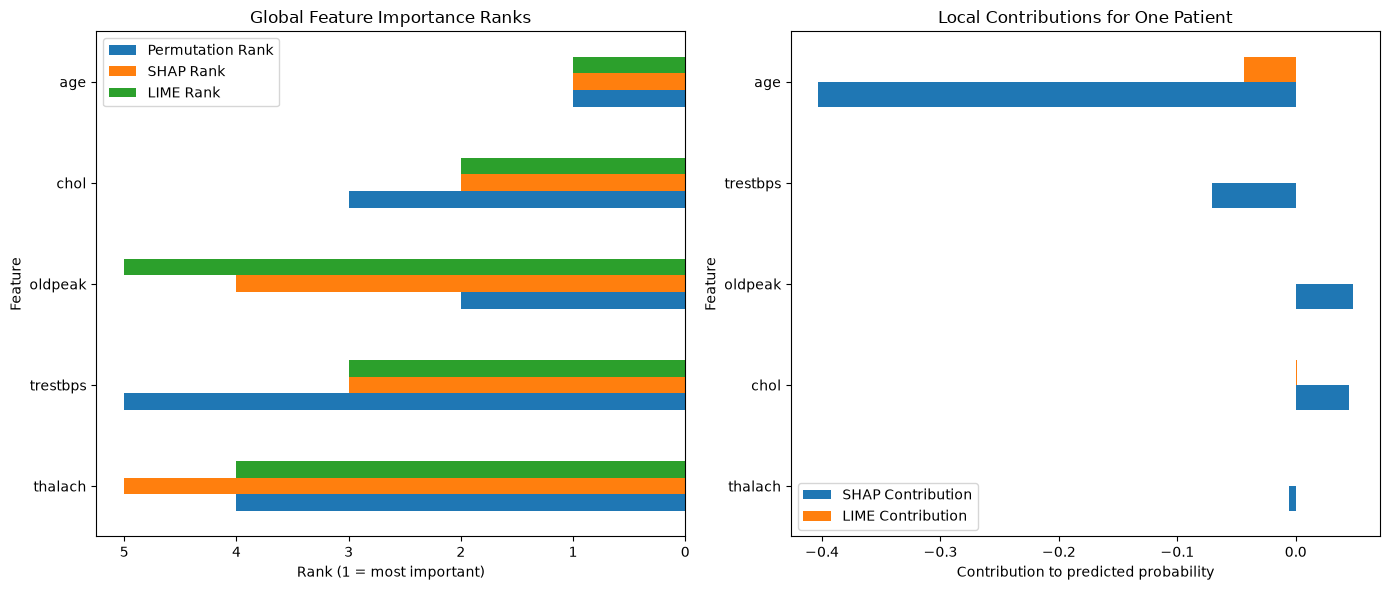

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

importance_df.sort_values("Average Rank", ascending=False)[
    ["Permutation Rank", "SHAP Rank", "LIME Rank"]
].plot(kind="barh", ax=axes[0])

axes[0].set_title("Global Feature Importance Ranks")
axes[0].set_xlabel("Rank (1 = most important)")
axes[0].set_ylabel("Feature")
axes[0].invert_xaxis()

local_df.sort_values("SHAP Absolute Impact").plot(
    x="Feature",
    y=["SHAP Contribution", "LIME Contribution"],
    kind="barh",
    ax=axes[1]
)

axes[1].set_title("Local Contributions for One Patient")
axes[1].set_xlabel("Contribution to predicted probability")
axes[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()